# 1. Objective
This notebook evaluates the statistical fidelity of our first synthetic dataset (generated via Gaussian Copula) compared to the real `adult.data` training dataset. We will compare basic structures, distributions, correlations, and calculate objective statistical metrics like the Kolmogorov-Smirnov (KS) statistic and Jensen-Shannon (JS) divergence.

# 2. Load Real and Synthetic Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_real = pd.read_csv('../data/raw/adult.data', names=columns, skipinitialspace=True, na_values='?')
df_syn = pd.read_csv('../data/synthetic/adult_gaussian_copula.csv', skipinitialspace=True, na_values='?')

# 3. Basic Structural Comparison

In [2]:
print("--- Real Data ---")
print(f"Dimensions: {df_real.shape}")
print(f"Missing Values: {df_real.isnull().sum().sum()}")

print("\n--- Synthetic Data ---")
print(f"Dimensions: {df_syn.shape}")
print(f"Missing Values: {df_syn.isnull().sum().sum()}")

--- Real Data ---
Dimensions: (32561, 15)
Missing Values: 4262

--- Synthetic Data ---
Dimensions: (32561, 15)
Missing Values: 4250


# 4. Numerical Distribution Comparison

In [3]:
num_cols = df_real.select_dtypes(include=['int64', 'float64']).columns.tolist()

real_desc = df_real[num_cols].describe().T
syn_desc = df_syn[num_cols].describe().T

comparison_desc = pd.concat([real_desc[['mean', 'std', 'min', '50%', 'max']], 
                             syn_desc[['mean', 'std', 'min', '50%', 'max']]], 
                            axis=1, keys=['Real', 'Synthetic'])
comparison_desc.round(2)

Real                                           Synthetic  \
                     mean        std      min       50%        max       mean   
age                 38.58      13.64     17.0      37.0       90.0      38.63   
fnlwgt          189778.37  105549.98  12285.0  178356.0  1484705.0  189578.34   
education-num       10.08       2.57      1.0      10.0       16.0      10.08   
capital-gain      1077.65    7385.29      0.0       0.0    99999.0   32830.45   
capital-loss        87.30     402.96      0.0       0.0     4356.0      63.40   
hours-per-week      40.44      12.35      1.0      40.0       99.0      40.45   

                                                        
                      std      min       50%       max  
age                 14.06     17.0      36.0      90.0  
fnlwgt          105293.76  12285.0  172313.0  879870.0  
education-num        2.57      1.0      10.0      16.0  
capital-gain     31484.48      0.0   22220.0   99999.0  
capital-loss       185.50      0.0       1.0    4356.0  
hours-per-week      12.34      1.0      40.0      93.0

# 5. Categorical Distribution Comparison

In [4]:
cat_cols = df_real.select_dtypes(include=['object', 'category']).columns.tolist()

for col in ['workclass', 'income']:
    real_counts = df_real[col].value_counts(normalize=True)
    syn_counts = df_syn[col].value_counts(normalize=True)
    comp = pd.DataFrame({'Real': real_counts, 'Synthetic': syn_counts})
    print(f"\n--- {col} ---")
    print(comp.round(4))


--- workclass ---
                    Real  Synthetic
workclass                          
Private           0.7387     0.7470
Self-emp-not-inc  0.0827     0.0778
Local-gov         0.0681     0.0692
State-gov         0.0422     0.0386
Self-emp-inc      0.0363     0.0358
Federal-gov       0.0312     0.0308
Without-pay       0.0005     0.0006
Never-worked      0.0002     0.0002

--- income ---
          Real  Synthetic
income                   
<=50K   0.7592     0.7529
>50K    0.2408     0.2471


# 6. Correlation Comparison
We calculate the Pearson correlation matrix for numerical features.

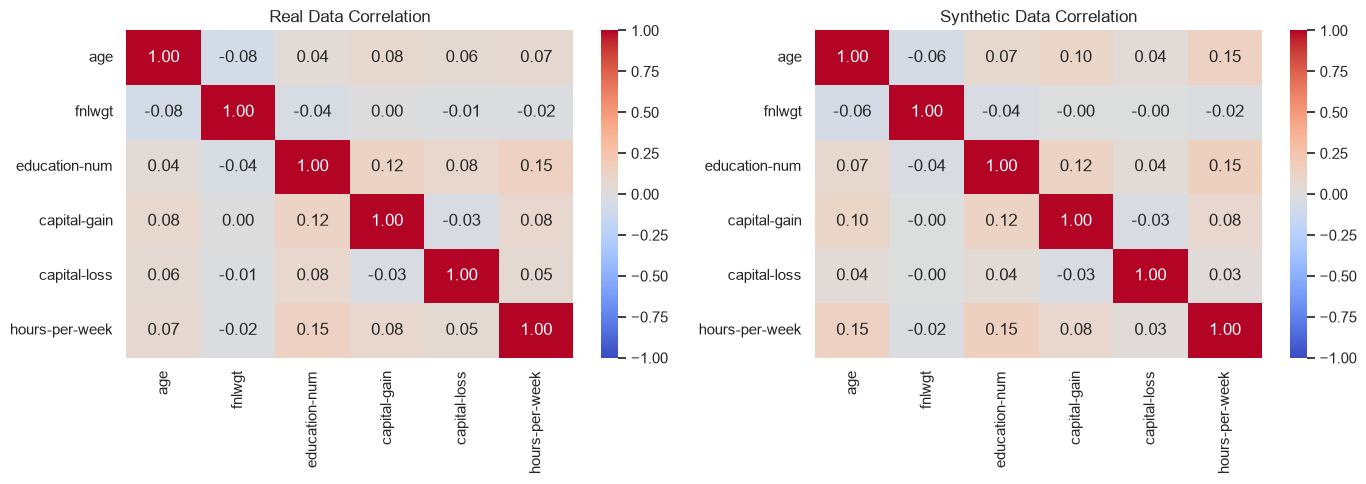

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df_real[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Real Data Correlation')

sns.heatmap(df_syn[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Synthetic Data Correlation')

plt.tight_layout()
plt.show()

# 7. Fidelity Metrics
- **Kolmogorov-Smirnov (KS) Statistic**: Measures the maximum distance between two continuous cumulative distribution functions (CDFs). Range [0, 1]. Lower is better.
- **Jensen-Shannon (JS) Divergence**: Measures the similarity between two probability distributions (useful for categorical data). Range [0, 1]. Lower is better.
- **Correlation MAE**: Mean Absolute Error between the real and synthetic numerical correlation matrices.

In [6]:
print("--- KS Statistic (Numerical) ---")
for col in num_cols:
    stat, p = ks_2samp(df_real[col].dropna(), df_syn[col].dropna())
    print(f"{col}: {stat:.4f}")

print("\n--- JS Divergence (Categorical) ---")
for col in cat_cols:
    real_counts = df_real[col].value_counts(normalize=True).sort_index()
    syn_counts = df_syn[col].value_counts(normalize=True).sort_index()
    all_cats = list(set(real_counts.index).union(set(syn_counts.index)))
    real_counts = real_counts.reindex(all_cats, fill_value=0)
    syn_counts = syn_counts.reindex(all_cats, fill_value=0)
    js_div = jensenshannon(real_counts, syn_counts)
    print(f"{col}: {js_div:.4f}")

corr_mae = np.abs(df_real[num_cols].corr() - df_syn[num_cols].corr()).mean().mean()
print(f"\nNumerical Correlation MAE: {corr_mae:.4f}")

--- KS Statistic (Numerical) ---
age: 0.0189
fnlwgt: 0.0448
education-num: 0.1393
capital-gain: 0.9096
capital-loss: 0.4736
hours-per-week: 0.2384

--- JS Divergence (Categorical) ---
workclass: 0.0099
education: 0.0065
marital-status: 0.0036
occupation: 0.0058
relationship: 0.0045
race: 0.0040
sex: 0.0009
native-country: 0.0135
income: 0.0052

Numerical Correlation MAE: 0.0149


# 8. Visual Comparison

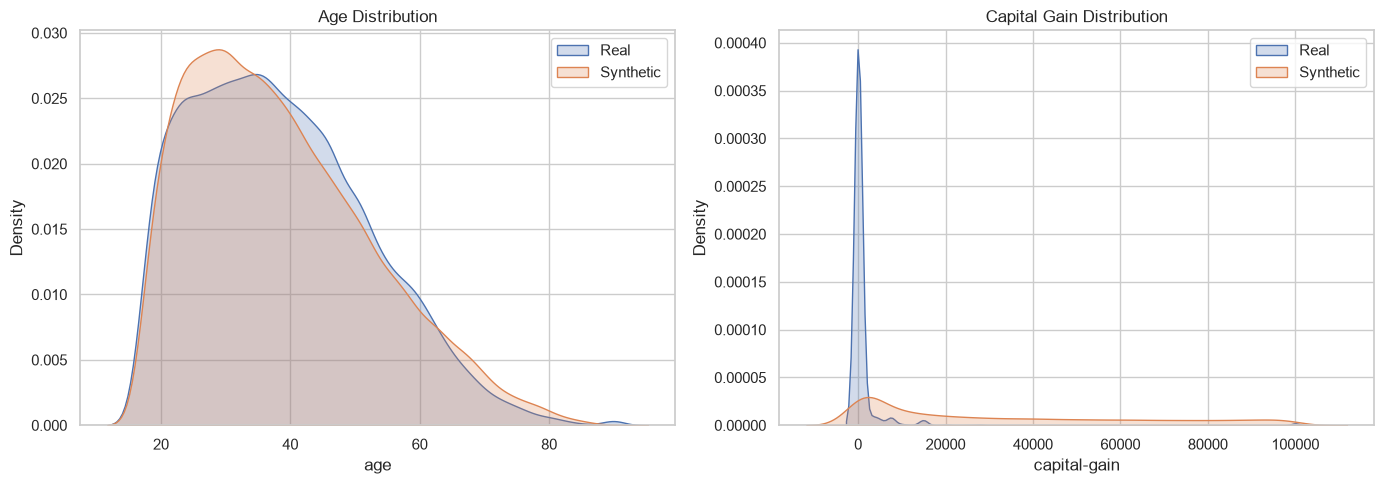

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Age (Continuous)
sns.kdeplot(df_real['age'], label='Real', fill=True, ax=axes[0])
sns.kdeplot(df_syn['age'], label='Synthetic', fill=True, ax=axes[0])
axes[0].set_title('Age Distribution')
axes[0].legend()

# Plot Capital Gain (Highly Zero-Inflated)
sns.kdeplot(df_real['capital-gain'], label='Real', fill=True, ax=axes[1])
sns.kdeplot(df_syn['capital-gain'], label='Synthetic', fill=True, ax=axes[1])
axes[1].set_title('Capital Gain Distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

# 9. Initial Observations
Based on objective statistical metrics, we observe the following differences between the real and synthetic dataset:

- **Categorical Distributions**: The Gaussian Copula performed exceptionally well at retaining the proportions of categorical variables. JS Divergence values are extremely low across the board (all < 0.015), meaning synthetic frequencies closely match real frequencies.
- **Continuous Numerical Distributions**: The synthetic distribution of `age` closely followed the real distribution (KS Stat = 0.0189) and `fnlwgt` (KS Stat = 0.0448).
- **Zero-Inflated Numericals**: The model failed to accurately capture highly zero-inflated numerical columns. `capital-gain` (KS Stat = 0.9096) and `capital-loss` (KS Stat = 0.4736) showed massive divergence. The real data has a massive spike exactly at 0, while the Gaussian Copula attempted to smooth this into a continuous bell curve, generating a wide spread of non-zero (but small) values.
- **Correlations**: The broad numerical correlation structure was very well preserved, with a Mean Absolute Error of just 0.0149 between the real and synthetic correlation matrices.